# Visualización de Grandes Bases de Datos — Tarea 1.0
## Gráfica de caja de Tukey e identificación de datos atípicos (método IQR)

**Carlos Pulido Rosas — MCD CUCEA · 3er semestre**

Variable: **Monóxido de carbono (CO)** · Estación **Country (COU)** — la más cercana al
domicilio (Quintas del Federalismo, Zapopan; ≈ 1.05 km). Dataset: calidad del aire ZMG 2024 (SIMAJ).

Objetivos: (1) todos los estadísticos del box-plot de Tukey; (2) la gráfica de caja;
(3) los datos atípicos por el método del rango intercuartil (IQR).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = r"../datos/BD_2024_calidad_aire.xlsx"
df = pd.read_excel(DATA, sheet_name="Data")
print("Estaciones que miden CO (conteo de lecturas válidas):")
print(df.assign(CO=pd.to_numeric(df.CO, errors="coerce"))
        .groupby("STATION").CO.count().sort_values(ascending=False).head(8))

Estaciones que miden CO (conteo de lecturas válidas):
STATION
CEN    8417
LDO    8209
MIR    8117
PIN    3078
ATM    3078
OBL    2702
SMT    2677
SFE    2464
Name: CO, dtype: int64


### Selección de la estación más cercana al domicilio
De las estaciones que miden CO, **Country (COU)** es la más próxima al domicilio
(≈ 1.05 km, vs. 4.5 km de la siguiente). Se filtra CO y se descartan lecturas faltantes.

In [2]:
sub = df.loc[df.STATION == "COU", ["DATE", "HOUR", "CO"]].copy()
sub["CO"] = pd.to_numeric(sub["CO"], errors="coerce")
sub = sub.dropna(subset=["CO"])
s = sub["CO"]
print(f"n observaciones válidas de CO en COU: {len(s)}")

n observaciones válidas de CO en COU: 578


### Estadísticos de la gráfica de caja de Tukey
Resumen de cinco números + IQR + cercas (Q1−1.5·IQR, Q3+1.5·IQR) + bigotes (valores adyacentes).

In [3]:
q1, q2, q3 = np.percentile(s, [25, 50, 75])
iqr = q3 - q1
lf, uf = q1 - 1.5*iqr, q3 + 1.5*iqr
whis_lo = s[s >= lf].min()
whis_hi = s[s <= uf].max()

stats = pd.Series({
    "n": len(s), "min": s.min(), "Q1": q1, "mediana (Q2)": q2, "Q3": q3,
    "max": s.max(), "media": s.mean(), "IQR": iqr,
    "cerca inferior": lf, "cerca superior": uf,
    "bigote inferior": whis_lo, "bigote superior": whis_hi,
})
stats.round(3)

n                  578.000
min                  0.031
Q1                   0.380
mediana (Q2)         0.501
Q3                   0.652
max                  1.675
media                0.547
IQR                  0.272
cerca inferior      -0.028
cerca superior       1.061
bigote inferior      0.031
bigote superior      1.046
dtype: float64

### Datos atípicos por el método IQR
Un dato es atípico si cae fuera de las cercas: `CO < Q1−1.5·IQR` o `CO > Q3+1.5·IQR`.

In [4]:
out = sub[(s < lf) | (s > uf)].sort_values("CO", ascending=False)
print(f"Datos atípicos: {len(out)}  (inferiores={int((s<lf).sum())}, superiores={int((s>uf).sum())})")
print(f"Rango de los atípicos: {out.CO.min():.3f} a {out.CO.max():.3f} ppm")
out.assign(FECHA=pd.to_datetime(out.DATE).dt.strftime('%Y-%m-%d')).head(10)[["FECHA","HOUR","CO"]]

Datos atípicos: 30  (inferiores=0, superiores=30)
Rango de los atípicos: 1.077 a 1.675 ppm


,FECHA,HOUR,CO
32757,2024-09-23,21,1.675
32793,2024-09-25,9,1.645
32347,2024-09-06,19,1.485
32504,2024-09-13,8,1.433
32348,2024-09-06,20,1.426
32661,2024-09-19,21,1.423
32503,2024-09-13,7,1.391
32264,2024-09-03,8,1.381
32755,2024-09-23,19,1.360
32630,2024-09-18,14,1.355


### Gráfica de caja de Tukey

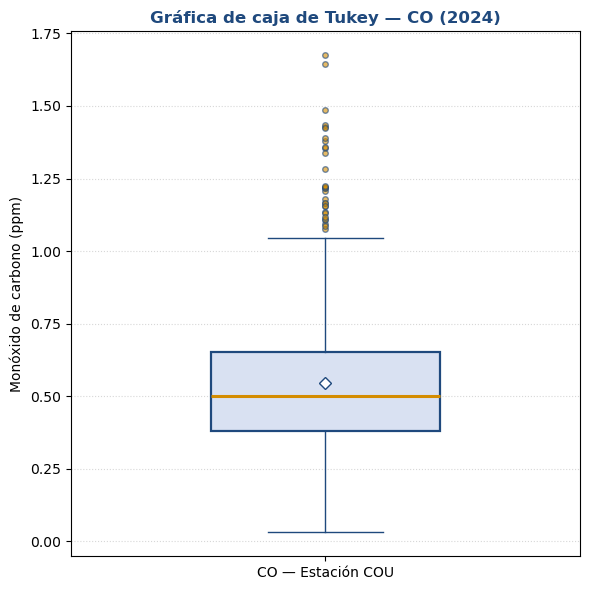

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.boxplot(s, vert=True, widths=0.45, whis=1.5, patch_artist=True, showmeans=True,
           boxprops=dict(facecolor="#D9E1F2", edgecolor="#1F497D", linewidth=1.6),
           medianprops=dict(color="#D48C00", linewidth=2.2),
           whiskerprops=dict(color="#1F497D"), capprops=dict(color="#1F497D"),
           flierprops=dict(marker="o", markerfacecolor="#D48C00",
                           markeredgecolor="#1F497D", markersize=4, alpha=0.6),
           meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="#1F497D"))
ax.set_xticks([1]); ax.set_xticklabels(["CO — Estación COU"])
ax.set_ylabel("Monóxido de carbono (ppm)")
ax.set_title("Gráfica de caja de Tukey — CO (2024)", color="#1F497D", weight="bold")
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout(); plt.show()

### Conclusión
Distribución asimétrica a la derecha (media > mediana); **30 atípicos (~5.2 %)**, todos en la
cola superior (1.077–1.675 ppm). El máximo (1.675 ppm) está muy por debajo del límite
NOM-021-SSA1 (11 ppm/8 h). El entregable formal es el PDF en `../tareas/Tarea1/`.